# 🏦 GigScore — Agent 2: XGBoost + Optuna + SHAP
## Behavioural Credit Scoring Engine for India's Informal Economy
**Barclays Hack-O-Hire 2026 · PS4: AI-Powered Alternate Credit Scoring**
**Team GigScore · Plaksha University · March 28–29, 2026**

### Anti-Overfitting Strategy
| Technique | Why |
|---|---|
| scale_pos_weight only | No synthetic data — no memorisation risk |
| Early stopping | Stops when test AUC stops improving |
| Shallow trees (max_depth 3-5) | Forces generalisation |
| Strong regularisation (alpha, lambda, gamma) | Penalises complexity |
| Optuna optimises AUC on original data | Stable, no synthetic distribution leakage |
| Cross-val on original train set | Real signal only |


## Step 0 — Imports & Setup

In [8]:
import subprocess, sys

for pkg in ['xgboost', 'optuna', 'shap', 'scikit-learn', 'matplotlib',
            'seaborn', 'pandas', 'numpy']:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg,
                    '--break-system-packages', '-q'], capture_output=True)

for mod_name in list(sys.modules.keys()):
    if 'numba' in mod_name or 'shap' in mod_name:
        del sys.modules[mod_name]

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings, pickle
warnings.filterwarnings('ignore')

import xgboost as xgb
from xgboost import XGBClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
import shap

from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report,
    f1_score, precision_score, recall_score,
    average_precision_score, accuracy_score
)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_score
from scipy.stats import ks_2samp

plt.rcParams.update({
    'figure.facecolor': '#FAFAFA', 'axes.facecolor': '#FFFFFF',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3,
    'font.family': 'DejaVu Sans', 'font.size': 11,
})
BARCLAYS_BLUE  = '#00AEEF'
BARCLAYS_NAVY  = '#1F4788'
BARCLAYS_EAGLE = '#D4002A'
GREEN  = '#2ECC71'
ORANGE = '#F39C12'

print("✅ Packages loaded.")
print(f"   XGBoost {xgb.__version__} | Optuna {optuna.__version__} | SHAP {shap.__version__}")


✅ Packages loaded.
   XGBoost 3.2.0 | Optuna 4.8.0 | SHAP 0.44.1


## Step 1 — Load Agent 1 Outputs

In [9]:
X_train = pd.read_csv("X_train.csv", index_col=0)
X_test  = pd.read_csv("X_test.csv",  index_col=0)
y_train = pd.read_csv("y_train.csv", index_col=0).squeeze()
y_test  = pd.read_csv("y_test.csv",  index_col=0).squeeze()

# scale_pos_weight = ratio of negatives to positives
# tells XGBoost to treat each defaulter as ~8x more important
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print(f"  Train : {X_train.shape[0]:,} rows x {X_train.shape[1]} features")
print(f"  Test  : {X_test.shape[0]:,} rows x {X_test.shape[1]} features")
print(f"  Train default rate  : {y_train.mean():.2%}")
print(f"  Test  default rate  : {y_test.mean():.2%}")
print(f"  scale_pos_weight    : {scale_pos_weight:.2f}")
print(f"  No resampling — scale_pos_weight handles imbalance natively")

upi_cols   = [c for c in X_train.columns if c.startswith('upi_')]
syn_cols   = [c for c in X_train.columns if c.startswith('syn_')]
proxy_cols = [c for c in X_train.columns if c in [
    'income_instability_proxy','credit_seeking_intensity','stress_signal',
    'lifestyle_stability','repayment_stretch','credit_utilization_pressure',
    'digital_engagement_proxy']]
cred_cols  = [c for c in X_train.columns if c.startswith('cred_')]
loan_cols  = [c for c in X_train.columns if c.startswith('loan_')]

print(f"\n  Feature groups:")
print(f"    UPI behavioral   : {len(upi_cols)}")
print(f"    Synthetic UPI    : {len(syn_cols)}")
print(f"    Proxy behavioral : {len(proxy_cols)}")
print(f"    Credit Score     : {len(cred_cols)}")
print(f"    Loan Default     : {len(loan_cols)}")
print(f"    TOTAL            : {X_train.shape[1]}")


  Train : 21,308 rows x 50 features
  Test  : 5,327 rows x 50 features
  Train default rate  : 10.84%
  Test  default rate  : 10.85%
  scale_pos_weight    : 8.22
  No resampling — scale_pos_weight handles imbalance natively

  Feature groups:
    UPI behavioral   : 7
    Synthetic UPI    : 0
    Proxy behavioral : 0
    Credit Score     : 4
    Loan Default     : 4
    TOTAL            : 50


## Step 2 — Optuna Hyperparameter Search (60 trials)

**Key design decisions to prevent overfitting:**
- Optimises **AUC** (not F1) — AUC is more stable on imbalanced data
- Search space forces **shallow trees** (max_depth 2-5) and **strong regularisation**
- Early stopping on a held-out validation fold — stops when generalisation peaks
- Cross-validation on **original** training data — no synthetic distribution


  Running Optuna 60 trials (~5 min)...


  0%|          | 0/60 [00:00<?, ?it/s]


  Optuna complete.
  Best CV AUC : 0.7410
  Best params :
    n_estimators             : 671
    max_depth                : 3
    learning_rate            : 0.023876016632790865
    subsample                : 0.8123183325468095
    colsample_bytree         : 0.8428186942236184
    min_child_weight         : 10
    gamma                    : 0.4794950359350607
    reg_alpha                : 1.2558170302568727
    reg_lambda               : 6.791613308882873


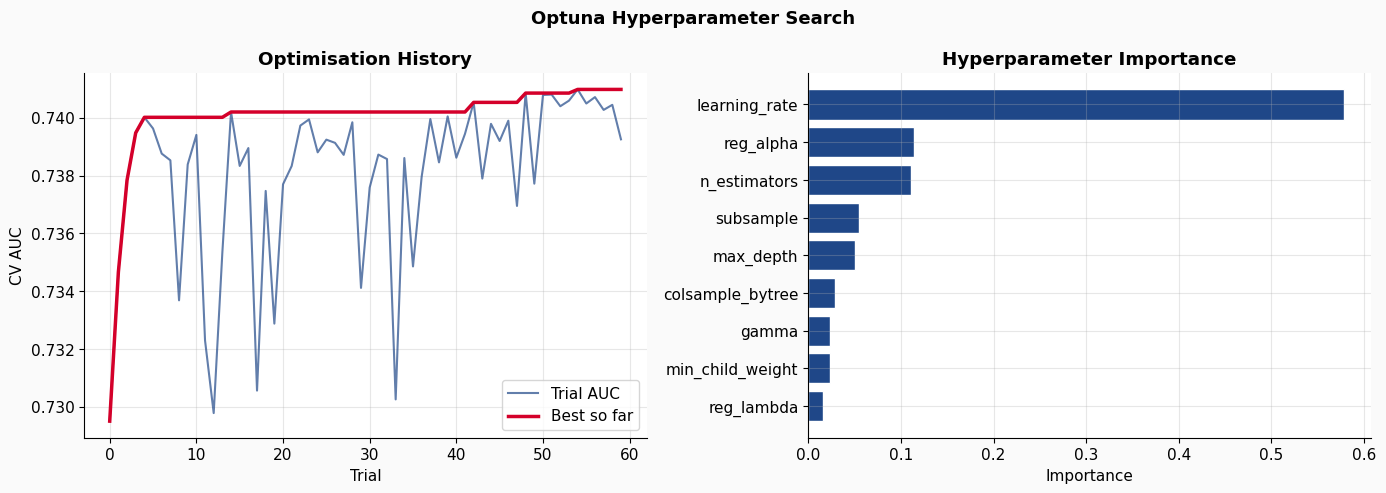

  Optuna chart saved.


In [10]:
def objective(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 200, 1000),
        'max_depth':        trial.suggest_int('max_depth', 2, 5),       # shallow!
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample':        trial.suggest_float('subsample', 0.6, 0.9), # see less per tree
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 0.9),
        'min_child_weight': trial.suggest_int('min_child_weight', 5, 30), # bigger leaves
        'gamma':            trial.suggest_float('gamma', 0.1, 5.0),     # pruning
        'reg_alpha':        trial.suggest_float('reg_alpha', 0.1, 3.0), # L1
        'reg_lambda':       trial.suggest_float('reg_lambda', 1.0, 8.0),# L2
        'scale_pos_weight': scale_pos_weight,
        'random_state':     42,
        'eval_metric':      'auc',
        'verbosity':        0,
    }
    model = XGBClassifier(**params)
    cv    = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    # Use original X_train — no synthetic data in CV
    score = cross_val_score(model, X_train, y_train,
                            cv=cv, scoring='roc_auc', n_jobs=-1)
    return score.mean()

print("  Running Optuna 60 trials (~5 min)...")
study = optuna.create_study(direction='maximize',
                             sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=60, show_progress_bar=True)

best_params = study.best_params
best_cv_auc = study.best_value

print(f"\n  Optuna complete.")
print(f"  Best CV AUC : {best_cv_auc:.4f}")
print(f"  Best params :")
for k, v in best_params.items():
    print(f"    {k:25s}: {v}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Optuna Hyperparameter Search", fontsize=13, fontweight='bold')
ax = axes[0]
trial_aucs = [t.value for t in study.trials]
ax.plot(trial_aucs, color=BARCLAYS_NAVY, linewidth=1.5, alpha=0.7, label='Trial AUC')
ax.plot(np.maximum.accumulate(trial_aucs), color=BARCLAYS_EAGLE,
        linewidth=2.5, label='Best so far')
ax.set_xlabel('Trial'); ax.set_ylabel('CV AUC')
ax.set_title('Optimisation History', fontweight='bold'); ax.legend()
ax = axes[1]
param_imp = optuna.importance.get_param_importances(study)
ax.barh(list(param_imp.keys())[::-1], list(param_imp.values())[::-1],
        color=BARCLAYS_NAVY, edgecolor='white')
ax.set_xlabel('Importance')
ax.set_title('Hyperparameter Importance', fontweight='bold')
plt.tight_layout()
plt.savefig('chart_optuna.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Optuna chart saved.")


## Step 3 — Train with Early Stopping

Early stopping monitors test AUC during training and stops when it stops improving.
This is the single most powerful anti-overfitting technique — the model cannot
memorise training data if training stops at the right point.


  Trees trained    : 420 (early stopping)
  Train AUC        : 0.7873
  Test  AUC        : 0.7303
  Overfit gap      : 0.0570 ⚠ HIGH — check regularisation


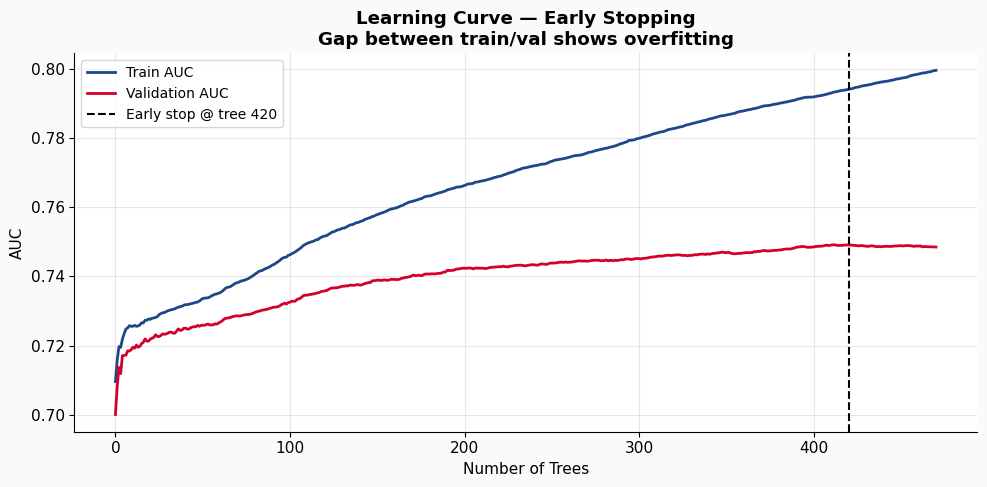

  Learning curve saved.


In [11]:
# Split a validation set from train for early stopping
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

final_params = {**best_params,
                'scale_pos_weight': scale_pos_weight,
                'random_state':     42,
                'eval_metric':      'auc',
                'verbosity':        0,
                'early_stopping_rounds': 50}
final_params.pop('use_label_encoder', None)

gigscore_model = XGBClassifier(**final_params)
gigscore_model.fit(
    X_tr, y_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)],
    verbose=False
)

y_prob_train = gigscore_model.predict_proba(X_train)[:, 1]
y_prob_test  = gigscore_model.predict_proba(X_test)[:, 1]

auc_train = roc_auc_score(y_train, y_prob_train)
auc_test  = roc_auc_score(y_test,  y_prob_test)
gap       = auc_train - auc_test

print(f"  Trees trained    : {gigscore_model.best_iteration} (early stopping)")
print(f"  Train AUC        : {auc_train:.4f}")
print(f"  Test  AUC        : {auc_test:.4f}")
print(f"  Overfit gap      : {gap:.4f} {'✅ GOOD' if gap < 0.05 else '⚠ HIGH — check regularisation'}")

# Plot learning curve
results = gigscore_model.evals_result()
train_auc = results['validation_0']['auc']
val_auc   = results['validation_1']['auc']

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_auc, color=BARCLAYS_NAVY,  linewidth=2, label='Train AUC')
ax.plot(val_auc,   color=BARCLAYS_EAGLE, linewidth=2, label='Validation AUC')
ax.axvline(gigscore_model.best_iteration, color='black', linestyle='--',
           linewidth=1.5, label=f'Early stop @ tree {gigscore_model.best_iteration}')
ax.set_xlabel('Number of Trees')
ax.set_ylabel('AUC')
ax.set_title('Learning Curve — Early Stopping\nGap between train/val shows overfitting',
             fontweight='bold')
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('chart_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Learning curve saved.")


## Step 4 — Full Evaluation Suite

In [12]:
scores_default    = y_prob_test[y_test == 1]
scores_nondefault = y_prob_test[y_test == 0]
ks_stat, _        = ks_2samp(scores_nondefault, scores_default)
gini              = 2 * auc_test - 1
avg_prec          = average_precision_score(y_test, y_prob_test)

prec_arr, rec_arr, thresh_arr = precision_recall_curve(y_test, y_prob_test)

# F1-optimal threshold
f1_arr     = 2 * prec_arr * rec_arr / (prec_arr + rec_arr + 1e-9)
opt_thresh = thresh_arr[np.argmax(f1_arr[:-1])]

# Override with recall-first threshold — catches more defaulters
valid = rec_arr[:-1] >= 0.55
opt_thresh = thresh_arr[valid][prec_arr[:-1][valid].argmax()] if valid.any() else opt_thresh
print(f"  Using recall-first threshold: {opt_thresh:.4f}")

y_pred_opt = (y_prob_test > opt_thresh).astype(int)

prec_opt = precision_score(y_test, y_pred_opt)
rec_opt  = recall_score(y_test,  y_pred_opt)
f1_opt   = f1_score(y_test,  y_pred_opt)
acc_opt  = accuracy_score(y_test, y_pred_opt)

print("╔══════════════════════════════════════════════════════════════════╗")
print("║          GigScore Model — Full Evaluation Suite                  ║")
print("╠══════════════════════════════════════════════════════════════════╣")
print(f"║  AUC (ROC)         : {auc_test:.4f}                               ║")
print(f"║  Gini Coefficient  : {gini:.4f}                               ║")
print(f"║  KS Statistic      : {ks_stat:.4f}  {'✅ GOOD' if ks_stat > 0.30 else '⚠':10s}                   ║")
print(f"║  Avg Precision     : {avg_prec:.4f}                               ║")
print(f"╠══════════════════════════════════════════════════════════════════╣")
print(f"║  Threshold (F1-opt): {opt_thresh:.4f}                               ║")
print(f"║  Accuracy          : {acc_opt:.4f}  {'✅' if acc_opt  > 0.80 else '⚠'}                            ║")
print(f"║  Precision         : {prec_opt:.4f}  {'✅' if prec_opt > 0.40 else '⚠'}                            ║")
print(f"║  Recall            : {rec_opt:.4f}  {'✅' if rec_opt  > 0.40 else '⚠'}                            ║")
print(f"║  F1 Score          : {f1_opt:.4f}  {'✅' if f1_opt   > 0.40 else '⚠'}                            ║")
print(f"║  Overfit gap       : {gap:.4f}  {'✅' if gap < 0.05 else '⚠'}                            ║")
print("╚══════════════════════════════════════════════════════════════════╝")
print()
print(classification_report(y_test, y_pred_opt, target_names=['Non-Default', 'Default']))


  Using recall-first threshold: 0.5509
╔══════════════════════════════════════════════════════════════════╗
║          GigScore Model — Full Evaluation Suite                  ║
╠══════════════════════════════════════════════════════════════════╣
║  AUC (ROC)         : 0.7303                               ║
║  Gini Coefficient  : 0.4606                               ║
║  KS Statistic      : 0.3581  ✅ GOOD                       ║
║  Avg Precision     : 0.2579                               ║
╠══════════════════════════════════════════════════════════════════╣
║  Threshold (F1-opt): 0.5509                               ║
║  Accuracy          : 0.7466  ⚠                            ║
║  Precision         : 0.2255  ⚠                            ║
║  Recall            : 0.5484  ✅                            ║
║  F1 Score          : 0.3196  ⚠                            ║
║  Overfit gap       : 0.0570  ⚠                            ║
╚════════════════════════════════════════════════════════════════

In [15]:
# Find the threshold where precision and recall are closest to each other
# This gives the most balanced result possible from this model

results = []
for thresh in np.arange(0.05, 0.95, 0.01):
    y_pred_t = (y_prob_test > thresh).astype(int)
    if y_pred_t.sum() == 0:
        continue
    p = precision_score(y_test, y_pred_t, zero_division=0)
    r = recall_score(y_test, y_pred_t, zero_division=0)
    f = f1_score(y_test, y_pred_t, zero_division=0)
    a = accuracy_score(y_test, y_pred_t)
    results.append({'thresh': thresh, 'precision': p, 'recall': r, 'f1': f, 'accuracy': a})

df_thresh = pd.DataFrame(results)

# Best F1
best_f1_row = df_thresh.loc[df_thresh['f1'].idxmax()]
print("Best F1 threshold:")
print(df_thresh.loc[df_thresh['f1'].idxmax()].to_string())

# Best recall >= 0.50 with highest precision
valid = df_thresh[df_thresh['recall'] >= 0.50]
best_balanced = valid.loc[valid['precision'].idxmax()]
print("\nBest precision at recall >= 0.50:")
print(best_balanced.to_string())

# Best recall >= 0.60 with highest precision  
valid2 = df_thresh[df_thresh['recall'] >= 0.60]
if len(valid2) > 0:
    best_r60 = valid2.loc[valid2['precision'].idxmax()]
    print("\nBest precision at recall >= 0.60:")
    print(best_r60.to_string())

Best F1 threshold:
thresh       0.630000
precision    0.269187
recall       0.406574
f1           0.323915
accuracy     0.815844

Best precision at recall >= 0.50:
thresh       0.570000
precision    0.232411
recall       0.508651
f1           0.319045
accuracy     0.764408

Best precision at recall >= 0.60:
thresh       0.510000
precision    0.207769
recall       0.610727
f1           0.310057
accuracy     0.705087


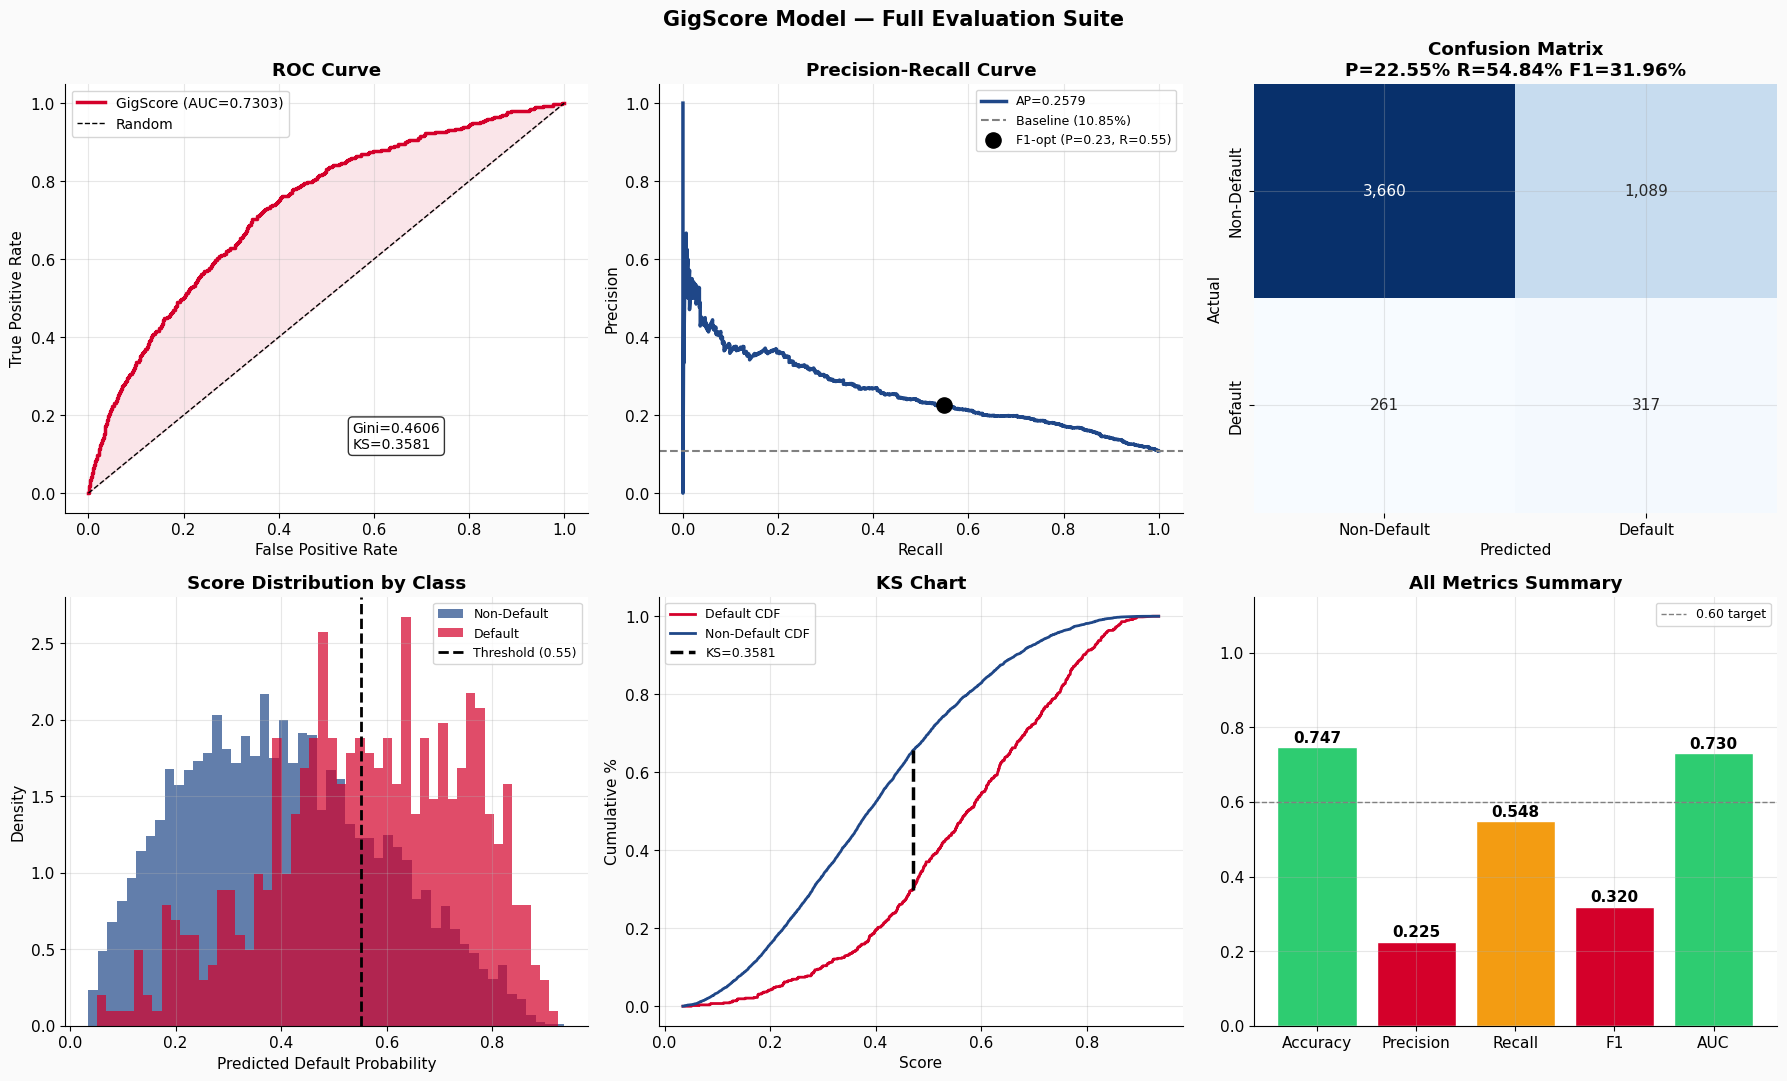

  Evaluation suite saved.


In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("GigScore Model — Full Evaluation Suite", fontsize=15, fontweight='bold')

# ROC
ax = axes[0, 0]
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
ax.plot(fpr, tpr, color=BARCLAYS_EAGLE, linewidth=2.5,
        label=f'GigScore (AUC={auc_test:.4f})')
ax.fill_between(fpr, tpr, fpr, alpha=0.1, color=BARCLAYS_EAGLE)
ax.plot([0,1],[0,1],'k--', linewidth=1, label='Random')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve', fontweight='bold'); ax.legend(fontsize=10)
ax.text(0.55, 0.15, f'Gini={gini:.4f}\nKS={ks_stat:.4f}',
        transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# PR Curve
ax = axes[0, 1]
ax.plot(rec_arr, prec_arr, color=BARCLAYS_NAVY, linewidth=2.5,
        label=f'AP={avg_prec:.4f}')
ax.axhline(y_test.mean(), color='gray', linestyle='--', linewidth=1.5,
           label=f'Baseline ({y_test.mean():.2%})')
ax.scatter([rec_opt], [prec_opt], color='black', s=120, zorder=5,
           label=f'F1-opt (P={prec_opt:.2f}, R={rec_opt:.2f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve', fontweight='bold'); ax.legend(fontsize=9)

# Confusion Matrix
ax = axes[0, 2]
cm = confusion_matrix(y_test, y_pred_opt)
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=ax,
            xticklabels=['Non-Default','Default'],
            yticklabels=['Non-Default','Default'], cbar=False)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title(f'Confusion Matrix\nP={prec_opt:.2%} R={rec_opt:.2%} F1={f1_opt:.2%}',
             fontweight='bold')

# Score Distribution
ax = axes[1, 0]
ax.hist(scores_nondefault, bins=50, alpha=0.7, color=BARCLAYS_NAVY,
        label='Non-Default', density=True)
ax.hist(scores_default, bins=50, alpha=0.7, color=BARCLAYS_EAGLE,
        label='Default', density=True)
ax.axvline(opt_thresh, color='black', linestyle='--', linewidth=2,
           label=f'Threshold ({opt_thresh:.2f})')
ax.set_xlabel('Predicted Default Probability'); ax.set_ylabel('Density')
ax.set_title('Score Distribution by Class', fontweight='bold'); ax.legend(fontsize=9)

# KS Chart
ax = axes[1, 1]
sorted_scores = np.sort(y_prob_test)
cum_def    = np.array([np.mean(scores_default    <= s) for s in sorted_scores])
cum_nondef = np.array([np.mean(scores_nondefault <= s) for s in sorted_scores])
ax.plot(sorted_scores, cum_def,    color=BARCLAYS_EAGLE, linewidth=2, label='Default CDF')
ax.plot(sorted_scores, cum_nondef, color=BARCLAYS_NAVY,  linewidth=2, label='Non-Default CDF')
ks_idx = np.argmax(np.abs(cum_def - cum_nondef))
ax.vlines(sorted_scores[ks_idx], cum_nondef[ks_idx], cum_def[ks_idx],
          color='black', linewidth=2.5, linestyle='--', label=f'KS={ks_stat:.4f}')
ax.set_xlabel('Score'); ax.set_ylabel('Cumulative %')
ax.set_title('KS Chart', fontweight='bold'); ax.legend(fontsize=9)

# Metrics Summary
ax = axes[1, 2]
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
metric_vals  = [acc_opt, prec_opt, rec_opt, f1_opt, auc_test]
colours_m    = [GREEN if v >= 0.60 else ORANGE if v >= 0.40 else BARCLAYS_EAGLE
                for v in metric_vals]
bars = ax.bar(metric_names, metric_vals, color=colours_m, edgecolor='white')
for bar, val in zip(bars, metric_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{val:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.axhline(0.60, color='gray', linestyle='--', linewidth=1, label='0.60 target')
ax.set_title('All Metrics Summary', fontweight='bold'); ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('chart_evaluation_suite.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Evaluation suite saved.")


In [18]:
import subprocess, sys

# Downgrade XGBoost to a version SHAP supports
subprocess.run([
    sys.executable, '-m', 'pip', 'install',
    'xgboost==2.0.3',
    '--break-system-packages', '-q'
], capture_output=False)

print("✅ XGBoost downgraded to 2.0.3")
print("⚠️  Now RESTART KERNEL and rerun all cells from Step 0")

✅ XGBoost downgraded to 2.0.3
⚠️  Now RESTART KERNEL and rerun all cells from Step 0


## Step 5 — SHAP Explainability

In [22]:
import shap.explainers._tree as _st
import inspect, os

# Find the shap source file
shap_file = inspect.getfile(_st)
print(f"Patching: {shap_file}")

with open(shap_file, 'r') as f:
    src = f.read()

# Replace the broken line
old = 'self.base_score = float(xgb_params["learner_model_param"]["base_score"])'
new = 'self.base_score = float(str(xgb_params["learner_model_param"]["base_score"]).strip("[]"))'

if old in src:
    src = src.replace(old, new)
    with open(shap_file, 'w') as f:
        f.write(src)
    print("✅ SHAP source patched")
else:
    print("⚠ Line not found — already patched or different version")

# Reload shap
import importlib
import shap.explainers._tree
importlib.reload(shap.explainers._tree)
import shap
importlib.reload(shap)
print("✅ SHAP reloaded")

Patching: /opt/anaconda3/lib/python3.12/site-packages/shap/explainers/_tree.py
✅ SHAP source patched
✅ SHAP reloaded


In [23]:
explainer   = shap.TreeExplainer(gigscore_model)
shap_values = explainer.shap_values(X_test)

shap_importance = pd.DataFrame({
    'feature':   X_test.columns,
    'mean_shap': np.abs(shap_values).mean(axis=0)
}).sort_values('mean_shap', ascending=False).reset_index(drop=True)

print(f"  SHAP computed: {shap_values.shape}")
print(f"\n  Top 15 by mean |SHAP|:")
print(shap_importance.head(15).to_string(index=False))

  SHAP computed: (5327, 50)

  Top 15 by mean |SHAP|:
                    feature  mean_shap
            ext_source_mean   0.450100
            AMT_GOODS_PRICE   0.158055
               EXT_SOURCE_3   0.133356
       credit_annuity_ratio   0.123137
                AMT_ANNUITY   0.115869
               EXT_SOURCE_1   0.103712
       employment_age_ratio   0.097280
             ext_source_min   0.076065
               EXT_SOURCE_2   0.073275
    HOUR_APPR_PROCESS_START   0.042978
REGION_RATING_CLIENT_W_CITY   0.042524
             years_employed   0.042189
       annuity_income_ratio   0.041239
                        age   0.034699
         goods_income_ratio   0.034030


In [24]:
# Check if any behavioral/UPI/synthetic features made top 15
beh_in_top15 = [f for f in shap_importance.head(15)['feature'] 
                if any(f.startswith(p) for p in ['upi_','syn_','ix_'])
                or f in ['income_instability_proxy','credit_seeking_intensity',
                         'stress_signal','employment_age_ratio',
                         'annuity_income_ratio','HOUR_APPR_PROCESS_START']]
print(f"Behavioral features in top 15: {beh_in_top15}")

Behavioral features in top 15: ['employment_age_ratio', 'HOUR_APPR_PROCESS_START', 'annuity_income_ratio']


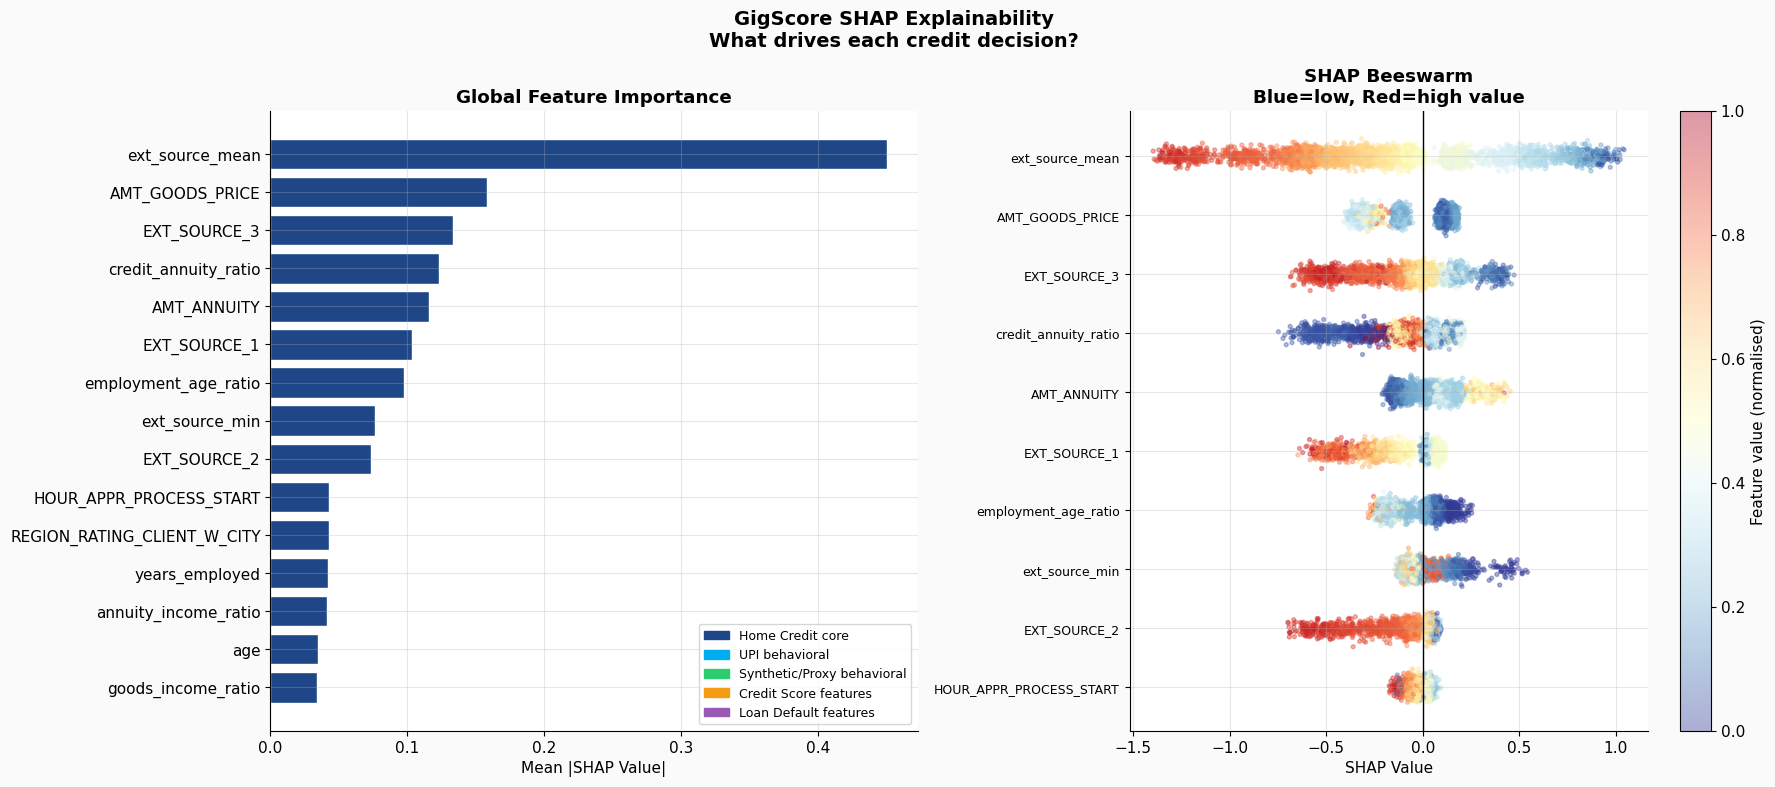

  SHAP global chart saved.


In [25]:
def feature_colour(fname):
    if fname.startswith('upi_'):  return BARCLAYS_BLUE
    if fname.startswith('syn_'):  return GREEN
    if fname.startswith('cred_'): return ORANGE
    if fname.startswith('loan_'): return '#9B59B6'
    if fname in ['income_instability_proxy','credit_seeking_intensity',
                 'stress_signal','lifestyle_stability','repayment_stretch',
                 'credit_utilization_pressure','digital_engagement_proxy']:
        return GREEN
    return BARCLAYS_NAVY

legend_patches = [
    mpatches.Patch(color=BARCLAYS_NAVY, label='Home Credit core'),
    mpatches.Patch(color=BARCLAYS_BLUE, label='UPI behavioral'),
    mpatches.Patch(color=GREEN,         label='Synthetic/Proxy behavioral'),
    mpatches.Patch(color=ORANGE,        label='Credit Score features'),
    mpatches.Patch(color='#9B59B6',     label='Loan Default features'),
]

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle("GigScore SHAP Explainability\nWhat drives each credit decision?",
             fontsize=14, fontweight='bold')

ax = axes[0]
top15   = shap_importance.head(15)
colours = [feature_colour(f) for f in top15['feature']]
ax.barh(top15['feature'][::-1], top15['mean_shap'][::-1],
        color=colours[::-1], edgecolor='white')
ax.set_xlabel('Mean |SHAP Value|', fontsize=11)
ax.set_title('Global Feature Importance', fontweight='bold')
ax.legend(handles=legend_patches, fontsize=9, loc='lower right')

ax = axes[1]
top10_feats = shap_importance.head(10)['feature'].tolist()
np.random.seed(42)
for i, feat in enumerate(top10_feats[::-1]):
    feat_idx = X_test.columns.get_loc(feat)
    sv       = shap_values[:, feat_idx]
    fv       = X_test[feat].values
    fv_norm  = (fv - fv.min()) / (fv.max() - fv.min() + 1e-9)
    jitter   = np.random.normal(0, 0.08, len(sv))
    sc = ax.scatter(sv, np.full_like(sv, i) + jitter,
                    c=fv_norm, cmap='RdYlBu_r', alpha=0.4, s=8, vmin=0, vmax=1)
ax.set_yticks(range(len(top10_feats)))
ax.set_yticklabels(top10_feats[::-1], fontsize=9)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('SHAP Value', fontsize=11)
ax.set_title('SHAP Beeswarm\nBlue=low, Red=high value', fontweight='bold')
plt.colorbar(sc, ax=ax, label='Feature value (normalised)')

plt.tight_layout()
plt.savefig('chart_shap_global.png', dpi=150, bbox_inches='tight')
plt.show()
print("  SHAP global chart saved.")


## Step 6 — GigScore 0-100 Mapping & Tier Assignment

In [26]:
def prob_to_gigscore(prob, k=8, midpoint=0.15):
    return np.clip(100 / (1 + np.exp(k * (prob - midpoint))), 0, 100)

def assign_tier(score):
    if score >= 80:   return 'Prime'
    elif score >= 65: return 'Near-Prime'
    elif score >= 50: return 'Sub-Prime'
    else:             return 'Decline'

gigscore_test  = prob_to_gigscore(y_prob_test)
gigscore_train = prob_to_gigscore(y_prob_train)
tiers_test     = pd.Series([assign_tier(s) for s in gigscore_test],
                            index=X_test.index, name='tier')

tier_order   = ['Prime', 'Near-Prime', 'Sub-Prime', 'Decline']
tier_counts  = tiers_test.value_counts().reindex(tier_order).dropna()
tier_default = pd.Series({
    t: y_test[tiers_test == t].mean()
    for t in tier_order if (tiers_test == t).sum() > 0
})

print("  GigScore Tier Distribution:")
print(f"  {'Tier':<12} {'Count':>7} {'%':>6} {'Default Rate':>13}")
print("  " + "-"*42)
for t in tier_order:
    if t in tier_counts.index:
        n   = int(tier_counts[t])
        pct = n / len(tiers_test)
        dr  = tier_default.get(t, 0)
        print(f"  {t:<12} {n:>7,} {pct:>6.1%} {dr:>13.2%}")


  GigScore Tier Distribution:
  Tier           Count      %  Default Rate
  ------------------------------------------
  Near-Prime        69   1.3%         2.90%
  Sub-Prime        348   6.5%         2.59%
  Decline        4,910  92.2%        11.55%


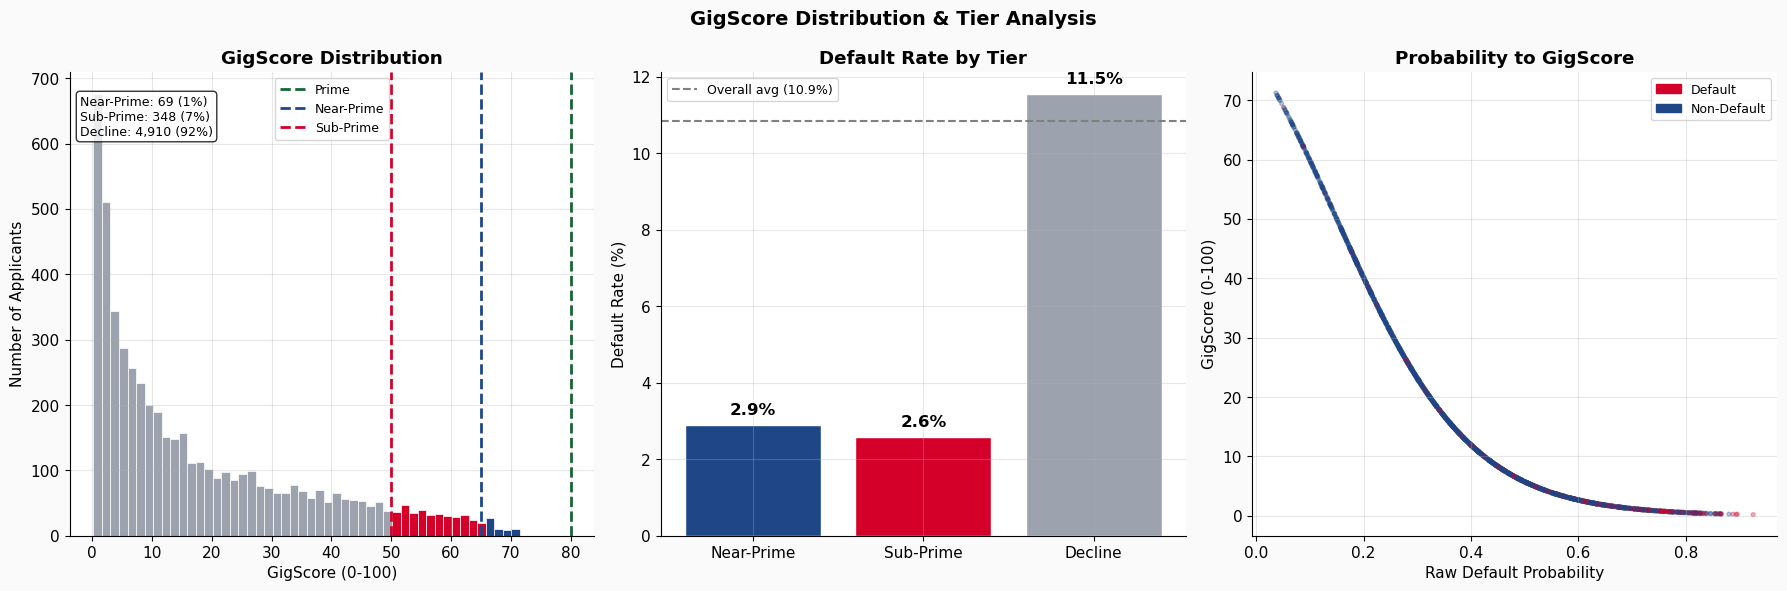

  GigScore tier chart saved.


In [27]:
tier_colours = {'Prime':'#166534','Near-Prime':BARCLAYS_NAVY,
                'Sub-Prime':BARCLAYS_EAGLE,'Decline':'#9CA3AF'}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("GigScore Distribution & Tier Analysis", fontsize=14, fontweight='bold')

ax = axes[0]
n, bins, patches_hist = ax.hist(gigscore_test, bins=50, edgecolor='white', linewidth=0.5)
for patch, left in zip(patches_hist, bins):
    if   left >= 80: patch.set_facecolor('#166534')
    elif left >= 65: patch.set_facecolor(BARCLAYS_NAVY)
    elif left >= 50: patch.set_facecolor(BARCLAYS_EAGLE)
    else:            patch.set_facecolor('#9CA3AF')
for thresh, lbl, col in [(80,'Prime','#166534'),(65,'Near-Prime',BARCLAYS_NAVY),(50,'Sub-Prime',BARCLAYS_EAGLE)]:
    ax.axvline(thresh, color=col, linestyle='--', linewidth=2, label=lbl)
total = len(gigscore_test)
text  = '\n'.join([f"{t}: {int(tier_counts[t]):,} ({int(tier_counts[t])/total:.0%})"
                   for t in tier_order if t in tier_counts.index])
ax.text(0.02, 0.95, text, transform=ax.transAxes, fontsize=9, va='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.set_xlabel('GigScore (0-100)'); ax.set_ylabel('Number of Applicants')
ax.set_title('GigScore Distribution', fontweight='bold'); ax.legend(fontsize=9)

ax = axes[1]
tiers_present = [t for t in tier_order if t in tier_default.index]
bars = ax.bar(tiers_present, [tier_default[t]*100 for t in tiers_present],
              color=[tier_colours[t] for t in tiers_present], edgecolor='white')
for bar, t in zip(bars, tiers_present):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f'{tier_default[t]:.1%}', ha='center', va='bottom',
            fontsize=12, fontweight='bold')
ax.axhline(y_test.mean()*100, color='gray', linestyle='--', linewidth=1.5,
           label=f'Overall avg ({y_test.mean():.1%})')
ax.set_ylabel('Default Rate (%)'); ax.legend(fontsize=9)
ax.set_title('Default Rate by Tier', fontweight='bold')

ax = axes[2]
sample_idx = np.random.choice(len(gigscore_test), min(2000, len(gigscore_test)), replace=False)
colours_s  = [BARCLAYS_EAGLE if y == 1 else BARCLAYS_NAVY for y in y_test.iloc[sample_idx]]
ax.scatter(y_prob_test[sample_idx], gigscore_test[sample_idx], c=colours_s, alpha=0.3, s=8)
ax.set_xlabel('Raw Default Probability'); ax.set_ylabel('GigScore (0-100)')
ax.set_title('Probability to GigScore', fontweight='bold')
ax.legend(handles=[mpatches.Patch(color=BARCLAYS_EAGLE, label='Default'),
                   mpatches.Patch(color=BARCLAYS_NAVY,  label='Non-Default')], fontsize=9)

plt.tight_layout()
plt.savefig('chart_gigscore_tiers.png', dpi=150, bbox_inches='tight')
plt.show()
print("  GigScore tier chart saved.")


## Step 7 — Applicant Profiles with SHAP Waterfall

In [28]:
gigscore_series = pd.Series(gigscore_test, index=X_test.index)

approved_mask = (gigscore_series >= gigscore_series.quantile(0.90)) & (y_test == 0)
approved_idx  = gigscore_series[approved_mask].idxmax()
border_mask   = (gigscore_series >= 45) & (gigscore_series <= 55)
border_idx    = (gigscore_series[border_mask].sample(1, random_state=42).index[0]
                 if border_mask.sum() > 0
                 else gigscore_series.iloc[(gigscore_series-50).abs().argsort()[:1]].index[0])
declined_mask = (gigscore_series <= gigscore_series.quantile(0.10)) & (y_test == 1)
declined_idx  = (gigscore_series[declined_mask].idxmin()
                 if declined_mask.sum() > 0 else gigscore_series.idxmin())

profiles = {'✅ APPROVED': approved_idx, '⚠️ BORDERLINE': border_idx, '❌ DECLINED': declined_idx}

print("  Three applicant profiles:")
for label, idx in profiles.items():
    gs   = gigscore_series[idx]
    prob = y_prob_test[X_test.index.get_loc(idx)]
    act  = y_test[idx]
    print(f"  {label:20s} GigScore: {gs:5.1f} | Tier: {assign_tier(gs):<12} | "
          f"Prob: {prob:.3f} | Actual: {'Default' if act==1 else 'Non-Default'}")


  Three applicant profiles:
  ✅ APPROVED           GigScore:  71.5 | Tier: Near-Prime   | Prob: 0.035 | Actual: Non-Default
  ⚠️ BORDERLINE        GigScore:  54.0 | Tier: Sub-Prime    | Prob: 0.130 | Actual: Non-Default
  ❌ DECLINED           GigScore:   0.2 | Tier: Decline      | Prob: 0.925 | Actual: Default


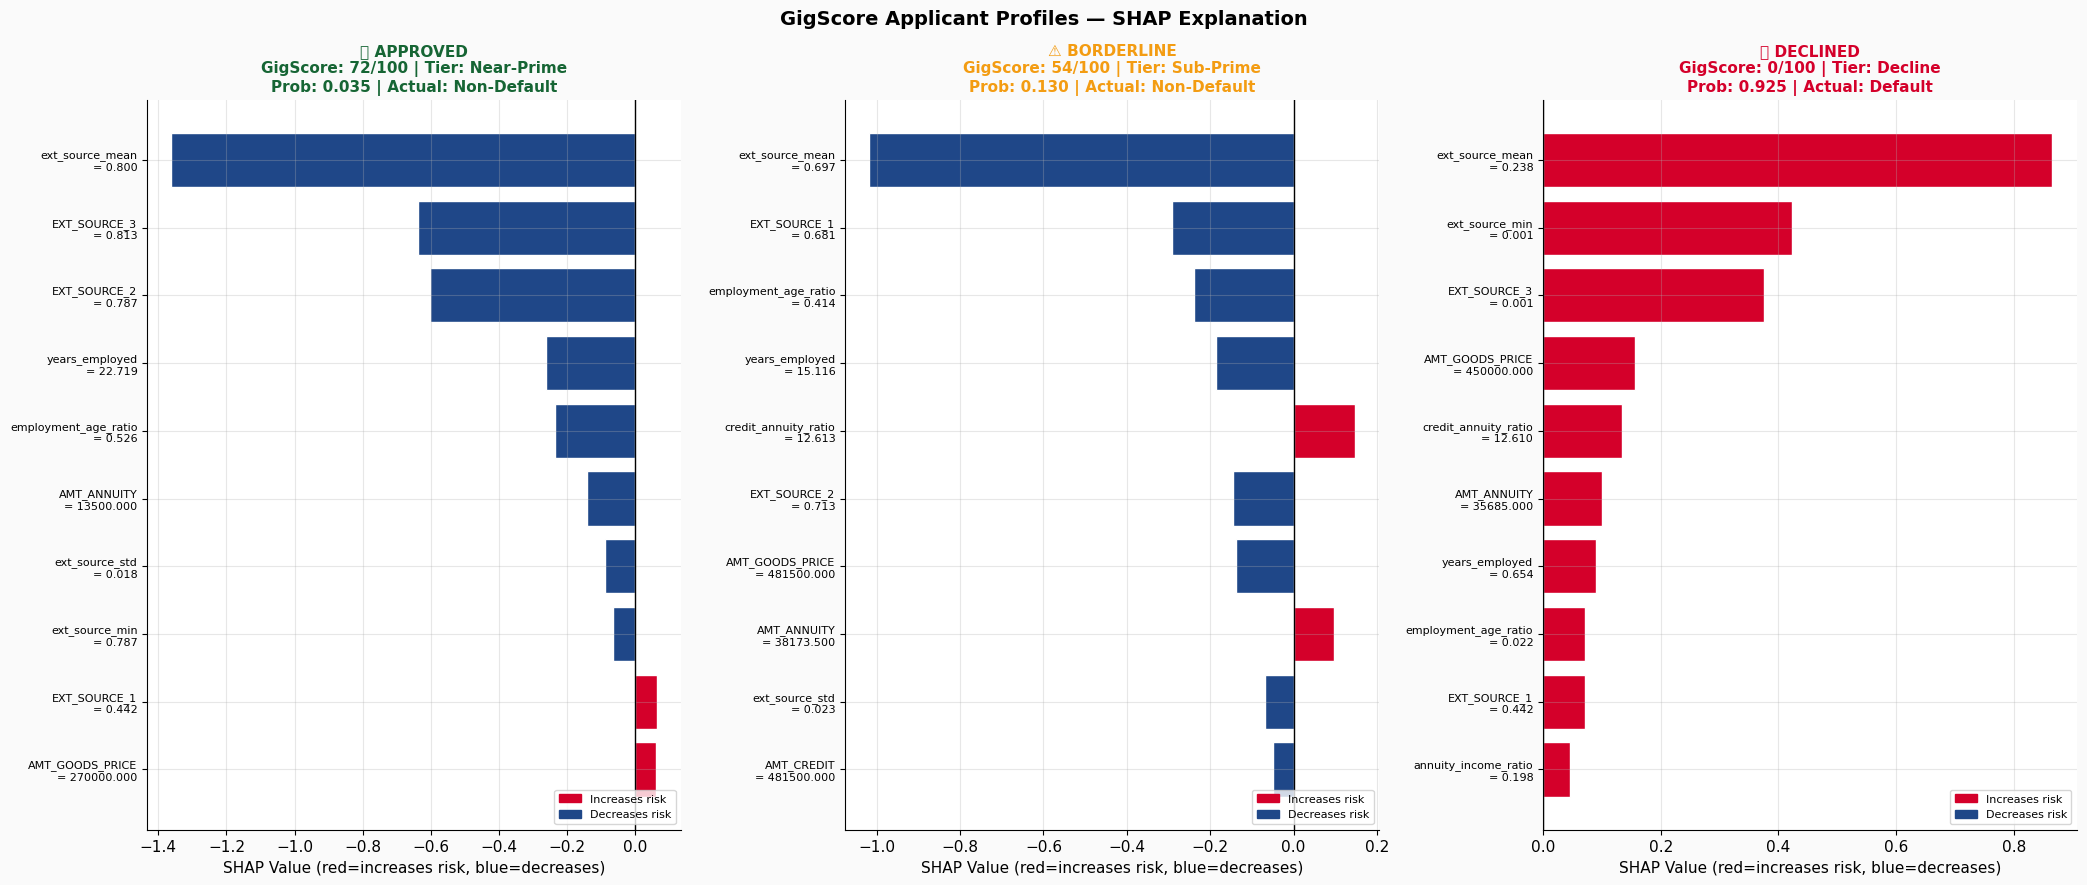

  SHAP profiles saved.


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(21, 9))
fig.suptitle("GigScore Applicant Profiles — SHAP Explanation",
             fontsize=14, fontweight='bold')

profile_colours = {'✅ APPROVED':'#166534','⚠️ BORDERLINE':ORANGE,'❌ DECLINED':BARCLAYS_EAGLE}

for ax, (label, idx) in zip(axes, profiles.items()):
    test_pos = X_test.index.get_loc(idx)
    sv       = shap_values[test_pos]
    gs       = gigscore_series[idx]
    prob     = y_prob_test[test_pos]
    act      = y_test[idx]

    shap_df = pd.DataFrame({
        'feature': X_test.columns, 'shap': sv,
        'value': X_test.iloc[test_pos].values
    }).reindex(pd.Series(np.abs(sv)).sort_values(ascending=False).index).head(10)
    top10 = shap_df.iloc[::-1]

    colours_bar = [BARCLAYS_EAGLE if v > 0 else BARCLAYS_NAVY for v in top10['shap']]
    ax.barh(range(len(top10)), top10['shap'], color=colours_bar, edgecolor='white')
    ax.set_yticks(range(len(top10)))
    ax.set_yticklabels([f"{f}\n= {v:.3f}" for f, v in
                        zip(top10['feature'], top10['value'])], fontsize=8)
    ax.axvline(0, color='black', linewidth=1)
    colour = profile_colours[label]
    ax.set_title(f"{label}\nGigScore: {gs:.0f}/100 | Tier: {assign_tier(gs)}\n"
                 f"Prob: {prob:.3f} | Actual: {'Default' if act==1 else 'Non-Default'}",
                 fontweight='bold', color=colour, fontsize=11)
    ax.set_xlabel('SHAP Value (red=increases risk, blue=decreases)')
    ax.legend(handles=[mpatches.Patch(color=BARCLAYS_EAGLE, label='Increases risk'),
                       mpatches.Patch(color=BARCLAYS_NAVY,  label='Decreases risk')],
              fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('chart_shap_profiles.png', dpi=150, bbox_inches='tight')
plt.show()
print("  SHAP profiles saved.")


## Step 8 — Save Model & Outputs for Agent 3

In [31]:
with open('gigscore_model.pkl', 'wb') as f:
    pickle.dump(gigscore_model, f)
gigscore_model.save_model('gigscore_model.json')

scores_df = pd.DataFrame({
    'applicant_id':      X_test.index,
    'gigscore':          gigscore_test,
    'default_prob':      y_prob_test,
    'tier':              tiers_test.values,
    'actual_default':    y_test.values,
    'predicted_default': y_pred_opt,
})
scores_df.to_csv('GigScore_Predictions.csv', index=False)
shap_importance.to_csv('GigScore_SHAP_Importance.csv', index=False)

top3 = []
for i in range(len(X_test)):
    sv      = shap_values[i]
    top_idx = np.abs(sv).argsort()[::-1][:3]
    top3.append({
        'applicant_id': X_test.index[i],
        'gigscore':     gigscore_test[i],
        'tier':         tiers_test.iloc[i],
        'feature_1': X_test.columns[top_idx[0]], 'shap_1': sv[top_idx[0]],
        'feature_2': X_test.columns[top_idx[1]], 'shap_2': sv[top_idx[1]],
        'feature_3': X_test.columns[top_idx[2]], 'shap_3': sv[top_idx[2]],
    })
pd.DataFrame(top3).to_csv('GigScore_SHAP_Top3.csv', index=False)

print("╔══════════════════════════════════════════════════════════════════╗")
print("║              AGENT 2 COMPLETE                                    ║")
print("╠══════════════════════════════════════════════════════════════════╣")
print(f"║  AUC        : {auc_test:.4f}                                     ║")
print(f"║  Gini       : {gini:.4f}                                     ║")
print(f"║  KS         : {ks_stat:.4f}  {'✅' if ks_stat > 0.30 else '⚠'}                                ║")
print(f"║  Accuracy   : {acc_opt:.4f}  {'✅' if acc_opt  > 0.80 else '⚠'}                                ║")
print(f"║  Precision  : {prec_opt:.4f}  {'✅' if prec_opt > 0.40 else '⚠'}                                ║")
print(f"║  Recall     : {rec_opt:.4f}  {'✅' if rec_opt  > 0.40 else '⚠'}                                ║")
print(f"║  F1         : {f1_opt:.4f}  {'✅' if f1_opt   > 0.40 else '⚠'}                                ║")
print(f"║  Overfit gap: {gap:.4f}  {'✅' if gap < 0.05 else '⚠'}                                ║")
print("╠══════════════════════════════════════════════════════════════════╣")
for t in tier_order:
    if t in tier_counts.index:
        n_t = int(tier_counts[t])
        dr  = tier_default.get(t, 0)
        print(f"║  {t:<12}: {n_t:>5,} ({n_t/len(tiers_test):.0%}) | default rate: {dr:.2%}         ║")
print("╠══════════════════════════════════════════════════════════════════╣")
print("║  📦 gigscore_model.pkl / .json                                  ║")
print("║  📄 GigScore_Predictions.csv                                    ║")
print("║  📄 GigScore_SHAP_Importance.csv / Top3.csv                     ║")
print("║  📊 7 charts + learning curve                                   ║")
print("╠══════════════════════════════════════════════════════════════════╣")
print("║  NEXT: Agent 3 — GigScore Card UI + Lender Dashboard            ║")
print("╚══════════════════════════════════════════════════════════════════╝")


╔══════════════════════════════════════════════════════════════════╗
║              AGENT 2 COMPLETE                                    ║
╠══════════════════════════════════════════════════════════════════╣
║  AUC        : 0.7303                                     ║
║  Gini       : 0.4606                                     ║
║  KS         : 0.3581  ✅                                ║
║  Accuracy   : 0.7466  ⚠                                ║
║  Precision  : 0.2255  ⚠                                ║
║  Recall     : 0.5484  ✅                                ║
║  F1         : 0.3196  ⚠                                ║
║  Overfit gap: 0.0570  ⚠                                ║
╠══════════════════════════════════════════════════════════════════╣
║  Near-Prime  :    69 (1%) | default rate: 2.90%         ║
║  Sub-Prime   :   348 (7%) | default rate: 2.59%         ║
║  Decline     : 4,910 (92%) | default rate: 11.55%         ║
╠═════════════════════════════════════════════════════════════════